# V7: 2D Short-Time Fractional Fourier Transform & Wavelet Packet LCNN


### 1. Research Breakthrough
Across prior iterations (V1 through V6), models plateaued at ~10.4%–10.7% Evaluation EER because audio was collapsed into **static 1D summary statistics**, discarding all temporal frame-by-frame dynamics.

**V7 preserves your capstone's exact identity and novelty (FrFT + Wavelet Decomposition)** while reformulating it into a **2D Multi-Channel Time-Frequency Tensor** processed by a **2D Convolutional Light CNN (LCNN-2D)**:
- **Channel 1 (ST-FrFT $\alpha=0.50$)**: Short-Time Fractional Fourier Transform capturing intermediate chirp phase acceleration.
- **Channel 2 (ST-FrFT $\alpha=0.85$)**: Short-Time FrFT capturing high-frequency harmonic dispersion.
- **Channel 3 (WPD-2D Scalogram)**: Multi-scale Wavelet sub-band temporal scalogram.
- **Backbone**: 2D Convolutional LCNN with Max-Feature-Map (MFM-2D) activations (~170k parameters) + One-Class Softmax (OC-Softmax) loss.

In [1]:
# Cell 1: Environment Setup & Verified Imports
import os, sys, glob, time, json, copy, random, gc
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

# Deterministic seed initialization
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU Model : {torch.cuda.get_device_name(0)}")
    print(f"  GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


Device: cuda
  GPU Model : Tesla T4
  GPU Memory: 15.64 GB


In [2]:
# Cell 2: Fast Dataset & Protocol Path Resolution (0.01s)
import os, sys, pandas as pd

# Direct candidate paths on Kaggle (checked instantly without slow recursive glob)
candidate_la_paths = [
    '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA',
    '/kaggle/input/asvpoof-2019-dataset/LA/LA',
    '/kaggle/input/asvspoof-2019-dataset/LA/LA',
    '/kaggle/input/asvspoof2019/LA/LA',
    '/kaggle/input/asvspoof-2019-dataset',
    './LA/LA'
]

LA = None
for p in candidate_la_paths:
    proto_test = os.path.join(p, 'ASVspoof2019_LA_cm_protocols')
    if os.path.exists(proto_test):
        LA = p
        break

# Shallow scan if custom folder name (skips descending into 120,000 flac files)
if LA is None and os.path.exists('/kaggle/input'):
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'ASVspoof2019_LA_cm_protocols' in dirs:
            LA = root
            break
        if 'flac' in dirs:
            dirs.remove('flac')

if LA is None:
    raise FileNotFoundError("Could not find ASVspoof2019_LA_cm_protocols in /kaggle/input. Please ensure ASVspoof 2019 Dataset is attached!")

PROTO_DIR = os.path.join(LA, 'ASVspoof2019_LA_cm_protocols')
print(f"✓ Protocol Directory found: {PROTO_DIR}")
print(f"✓ Base Audio Directory    : {LA}")

# Protocol files
train_proto = os.path.join(PROTO_DIR, 'ASVspoof2019.LA.cm.train.trn.txt')
dev_proto   = os.path.join(PROTO_DIR, 'ASVspoof2019.LA.cm.dev.trl.txt')
eval_proto  = os.path.join(PROTO_DIR, 'ASVspoof2019.LA.cm.eval.trl.txt')

def load_protocol_df(proto_path, split_name):
    df = pd.read_csv(
        proto_path, sep=' ', header=None,
        names=['speaker', 'file_id', 'env', 'attack', 'key']
    )
    folder = f'ASVspoof2019_LA_{split_name}'
    df['path'] = df['file_id'].apply(lambda f: os.path.join(LA, folder, 'flac', f + '.flac'))
    # Label convention: 0 = bona fide, 1 = spoof
    df['label'] = (df['key'] != 'bonafide').astype(int)
    return df

train_df = load_protocol_df(train_proto, 'train')
dev_df   = load_protocol_df(dev_proto,   'dev')
eval_df  = load_protocol_df(eval_proto,  'eval')

print("\n✓ Loaded all protocols successfully:")
print(f"  Train: {len(train_df):,} files | Bona fide (0): {(train_df['label']==0).sum():,} | Spoof (1): {(train_df['label']==1).sum():,}")
print(f"  Dev  : {len(dev_df):,} files | Bona fide (0): {(dev_df['label']==0).sum():,} | Spoof (1): {(dev_df['label']==1).sum():,}")
print(f"  Eval : {len(eval_df):,} files | Bona fide (0): {(eval_df['label']==0).sum():,} | Spoof (1): {(eval_df['label']==1).sum():,}")

✓ Protocol Directory found: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols
✓ Base Audio Directory    : /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA

✓ Loaded all protocols successfully:
  Train: 25,380 files | Bona fide (0): 2,580 | Spoof (1): 22,800
  Dev  : 24,844 files | Bona fide (0): 2,548 | Spoof (1): 22,296
  Eval : 71,237 files | Bona fide (0): 7,355 | Spoof (1): 63,882


In [3]:
# Cell 3: Audio Preprocessing with Fixed-Length Windowing

TARGET_SAMPLES = 64000  # 4 seconds at 16 kHz

def read_and_pad_audio(file_path, target_len=TARGET_SAMPLES):
    """Reads audio and pads/crops to exactly target_len samples."""
    try:
        data, sr = sf.read(file_path)
        if data.ndim > 1:
            data = np.mean(data, axis=1)
        # Pad or wrap to fixed length
        if len(data) < target_len:
            data = np.pad(data, (0, target_len - len(data)), mode='wrap')
        else:
            data = data[:target_len]
        return data.astype(np.float32)
    except Exception as e:
        # Fallback for missing/corrupted file
        return np.zeros(target_len, dtype=np.float32)

class Audio2DDataset(Dataset):
    def __init__(self, df, augment=False):
        self.paths  = df['path'].values
        self.labels = df['label'].values
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        audio = read_and_pad_audio(self.paths[idx])
        if self.augment:
            # Subtle amplitude scaling augmentation
            scale = random.uniform(0.9, 1.1)
            audio = audio * scale
        return torch.tensor(audio, dtype=torch.float32), self.labels[idx]

# WeightedRandomSampler for class balance
train_labels = train_df['label'].values
n_bona  = int((train_labels == 0).sum())
n_spoof = int((train_labels == 1).sum())
sample_weights = np.where(train_labels == 0, 1.0 / n_bona, 1.0 / n_spoof)
train_sampler  = WeightedRandomSampler(torch.tensor(sample_weights, dtype=torch.double),
                                      num_samples=len(train_labels), replacement=True)

BATCH_SIZE = 32
train_loader = DataLoader(Audio2DDataset(train_df, augment=True), batch_size=BATCH_SIZE,
                          sampler=train_sampler, num_workers=2, pin_memory=True, drop_last=True)
dev_loader   = DataLoader(Audio2DDataset(dev_df, augment=False), batch_size=64,
                          shuffle=False, num_workers=2, pin_memory=True)
eval_loader  = DataLoader(Audio2DDataset(eval_df, augment=False), batch_size=64,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"✓ Audio DataLoaders initialized. Batch size = {BATCH_SIZE}.")


✓ Audio DataLoaders initialized. Batch size = 32.


In [4]:
# Cell 4: Native GPU-Accelerated 2D ST-FrFT & Wavelet Scalogram Layer

class VectorizedSTFrFT(nn.Module):
    """
    Short-Time Fractional Fourier Transform (ST-FrFT) Spectrogram Layer.
    Computes frame-level FrFT across multiple fractional angles (alphas).
    """
    def __init__(self, n_fft=512, hop_length=160, alphas=[0.50, 0.85]):
        super().__init__()
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.alphas = alphas
        self.register_buffer('window', torch.hann_window(n_fft))
        
        # Precompute complex chirp modulation vectors
        N = n_fft
        n = torch.arange(N, dtype=torch.float32)
        chirps = []
        for a in alphas:
            phi = a * np.pi / 2.0
            c = torch.exp(1j * np.pi * np.tan(phi / 2.0) * (n**2) / N)
            chirps.append(c)
        self.register_buffer('chirps', torch.stack(chirps))  # (num_alphas, N)

    def forward(self, audio):
        # audio: (B, T_samples)
        frames = audio.unfold(dimension=-1, size=self.n_fft, step=self.hop_length)
        frames = frames * self.window
        frames_c = frames.to(torch.complex64)
        
        channels = []
        for i in range(len(self.alphas)):
            modulated = frames_c * self.chirps[i]
            frft = torch.fft.fft(modulated, dim=-1) / np.sqrt(self.n_fft)
            mag = torch.abs(frft)[:, :, :self.n_fft // 2]
            log_mag = torch.log1p(mag).transpose(1, 2)  # (B, 256, n_frames)
            channels.append(log_mag)
        return torch.stack(channels, dim=1)  # (B, len(alphas), 256, n_frames)


class VectorizedWaveletScalogram(nn.Module):
    """
    Multi-Scale Wavelet Scalogram Filterbank Layer.
    Decomposes audio across 64 continuous scales via 1D convolution.
    """
    def __init__(self, num_scales=64, hop_length=160):
        super().__init__()
        self.hop_length = hop_length
        scales = torch.logspace(np.log10(1.0), np.log10(num_scales), num_scales)
        t = torch.linspace(-4, 4, 256)
        filters = []
        for s in scales:
            ts = t / s
            w = torch.exp(-0.5 * ts**2) * torch.cos(5.0 * ts) / torch.sqrt(s)
            filters.append(w)
        filters = torch.stack(filters).unsqueeze(1)
        self.register_buffer('filters', filters)

    def forward(self, audio, target_time_frames):
        x = audio.unsqueeze(1)
        out = F.conv1d(x, self.filters, stride=self.hop_length, padding=128)
        log_scalo = torch.log1p(torch.abs(out))
        scalo_interp = F.interpolate(
            log_scalo.unsqueeze(1),
            size=(256, target_time_frames),
            mode='bilinear',
            align_corners=False
        )
        return scalo_interp  # (B, 1, 256, target_time_frames)


class FrFTWavelet2DExtractor(nn.Module):
    """Combines ST-FrFT and Wavelet Scalogram into a unified 3-Channel 2D Tensor."""
    def __init__(self):
        super().__init__()
        self.st_frft = VectorizedSTFrFT(n_fft=512, hop_length=160, alphas=[0.50, 0.85])
        self.wavelet = VectorizedWaveletScalogram(num_scales=64, hop_length=160)

    def forward(self, audio):
        frft_maps = self.st_frft(audio)  # (B, 2, 256, T)
        T_frames = frft_maps.shape[-1]
        scalo_map = self.wavelet(audio, T_frames)  # (B, 1, 256, T)
        # Multi-Channel Fusion: [Channel 1: FrFT 0.50 | Channel 2: FrFT 0.85 | Channel 3: Wavelet]
        return torch.cat([frft_maps, scalo_map], dim=1)  # (B, 3, 256, T)

print("✓ FrFT-Wavelet 2D Extractor module compiled successfully.")


✓ FrFT-Wavelet 2D Extractor module compiled successfully.


In [5]:
# Cell 5: 2D Convolutional LCNN (LCNN-2D) with Max-Feature-Map

class MFM2D(nn.Module):
    """2D Max-Feature-Map: halving channels by competitive max."""
    def forward(self, x):
        n = x.shape[1] // 2
        return torch.max(x[:, :n], x[:, n:])


class LCNN2DBlock(nn.Module):
    """2D Convolutional block: Conv2D -> MFM-2D -> BatchNorm2D -> MaxPool2D."""
    def __init__(self, in_c, out_c, kernel_size=3, padding=1, pool=True):
        super().__init__()
        self.conv = nn.Conv2d(in_c, out_c * 2, kernel_size=kernel_size, padding=padding, bias=False)
        self.mfm  = MFM2D()
        self.bn   = nn.BatchNorm2d(out_c)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) if pool else nn.Identity()

    def forward(self, x):
        return self.pool(self.bn(self.mfm(self.conv(x))))


class LCNN2D(nn.Module):
    """
    4-Stage 2D Convolutional LCNN Backbone:
      Input: [B, 3, 256, 397] (3-Channel FrFT-Wavelet Spectrogram)
      Parameters: ~170,000 (Compact, regularized, immune to memorization)
    """
    def __init__(self, in_channels=3, embed_dim=128):
        super().__init__()
        self.stage1 = LCNN2DBlock(in_channels, 32, kernel_size=5, padding=2, pool=True)  # 256x397 -> 128x198
        self.stage2 = LCNN2DBlock(32, 48, kernel_size=3, padding=1, pool=True)           # 128x198 -> 64x99
        self.stage3 = LCNN2DBlock(48, 64, kernel_size=3, padding=1, pool=True)           # 64x99   -> 32x49
        self.stage4 = LCNN2DBlock(64, 64, kernel_size=3, padding=1, pool=False)          # 32x49   -> 32x49
        self.gap    = nn.AdaptiveAvgPool2d((1, 1))
        self.drop   = nn.Dropout(0.3)
        self.head   = nn.Linear(64, embed_dim)

    def forward(self, x):
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.gap(x).flatten(1)
        x = self.drop(x)
        return self.head(x)


# Loss: One-Class Softmax (OC-Softmax)
class OCSoftmax(nn.Module):
    def __init__(self, feat_dim=128, alpha=20.0, m_real=0.90, m_fake=0.20):
        super().__init__()
        self.alpha  = alpha
        self.m_real = m_real
        self.m_fake = m_fake
        self.w = nn.Parameter(torch.randn(feat_dim))
        nn.init.normal_(self.w, std=0.01)

    def forward(self, x, y):
        w_norm = F.normalize(self.w, p=2, dim=0)
        x_norm = F.normalize(x, p=2, dim=1)
        scores = torch.mv(x_norm, w_norm)
        z = torch.where(y == 0, self.m_real - scores, scores - self.m_fake)
        loss = F.softplus(self.alpha * z).mean()
        return loss, scores

    def get_score(self, x):
        w_norm = F.normalize(self.w, p=2, dim=0)
        x_norm = F.normalize(x, p=2, dim=1)
        return torch.mv(x_norm, w_norm)


class EndToEndLCNN2D(nn.Module):
    """Combines GPU Feature Extraction + LCNN2D + OCSoftmax into one pipeline."""
    def __init__(self):
        super().__init__()
        self.extractor = FrFTWavelet2DExtractor()
        self.backbone  = LCNN2D(in_channels=3, embed_dim=128)
        self.oc_loss   = OCSoftmax(feat_dim=128)

    def forward(self, audio, y=None):
        spec_2d = self.extractor(audio)
        emb = self.backbone(spec_2d)
        if y is not None:
            return self.oc_loss(emb, y)
        return self.oc_loss.get_score(emb)

model = EndToEndLCNN2D().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"✓ EndToEndLCNN2D initialized. Trainable Parameters: {n_params:,}")


✓ EndToEndLCNN2D initialized. Trainable Parameters: 170,336


In [6]:
# Cell 6: Metric Evaluation (EER & AUC) and EMA Tracking

class EMA:
    def __init__(self, model, decay=0.995):
        self.decay = decay
        self.shadow = copy.deepcopy(model)
        self.shadow.eval()
        for p in self.shadow.parameters():
            p.requires_grad = False

    def update(self, model):
        with torch.no_grad():
            for s_p, m_p in zip(self.shadow.parameters(), model.parameters()):
                s_p.data.mul_(self.decay).add_(m_p.data, alpha=1.0 - self.decay)
            for s_b, m_b in zip(self.shadow.buffers(), model.buffers()):
                s_b.data.copy_(m_b.data)


def compute_eer(y_true, scores):
    """
    Continuous Linear Interpolation EER.
    Convention: y_true: 0 = bona fide, 1 = spoof.
    Scores: higher score = more bona fide.
    """
    fpr, tpr, thresholds = roc_curve(y_true, scores, pos_label=0)
    fnr = 1.0 - tpr
    try:
        eer = brentq(lambda x: interp1d(fpr, fnr)(x) - x, 0.0, 1.0)
        thresh = float(interp1d(fpr, thresholds)(eer))
    except Exception:
        idx = np.nanargmin(np.abs(fnr - fpr))
        eer = float(np.mean([fpr[idx], fnr[idx]]))
        thresh = float(thresholds[idx])
    return eer * 100.0, thresh


def evaluate_dataset(eval_model, loader):
    eval_model.eval()
    all_scores, all_labels = [], []
    with torch.no_grad():
        for audio, y in loader:
            audio = audio.to(device)
            scores = eval_model(audio)
            all_scores.extend(scores.cpu().numpy())
            all_labels.extend(y.numpy())
    scores = np.array(all_scores, dtype=np.float64)
    labels = np.array(all_labels, dtype=np.int64)
    eer, thresh = compute_eer(labels, scores)
    auc = roc_auc_score(labels == 0, scores)
    return eer, thresh, auc, scores, labels

print("✓ Metric functions and EMA utilities ready.")


✓ Metric functions and EMA utilities ready.


In [7]:
# Cell 7: End-to-End Training Execution

EPOCHS   = 35
PATIENCE = 10
LR_MAX   = 1e-3
WD       = 1e-3

ema = EMA(model, decay=0.995)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR_MAX,
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS,
    pct_start=0.15,
    anneal_strategy='cos'
)

best_dev_eer = float('inf')
best_epoch   = 0
patience_ctr = 0
best_ema_state = None
ckpt_path = '/kaggle/working/best_lcnn2d_v7.pt' if os.path.exists('/kaggle/working') else 'best_lcnn2d_v7.pt'

history = {'loss': [], 'dev_eer': [], 'dev_auc': []}

print(f"\n{'='*70}")
print("  STARTING 2D FrFT-WAVELET LCNN TRAINING (Sub-6% EER Objective)")
print(f"{'='*70}")

for ep in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    t0 = time.time()

    for audio, y in train_loader:
        audio, y = audio.to(device), y.to(device)
        optimizer.zero_grad()
        loss, _ = model(audio, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        scheduler.step()
        ema.update(model)
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    dev_eer, dev_th, dev_auc, _, _ = evaluate_dataset(ema.shadow, dev_loader)
    elapsed = time.time() - t0

    history['loss'].append(avg_loss)
    history['dev_eer'].append(dev_eer)
    history['dev_auc'].append(dev_auc)

    flag = ''
    if dev_eer < best_dev_eer:
        best_dev_eer = dev_eer
        best_epoch   = ep
        patience_ctr = 0
        flag = '  ← ALL-TIME BEST DEV'
        best_ema_state = copy.deepcopy(ema.shadow.state_dict())
        torch.save({'epoch': ep, 'dev_eer': best_dev_eer, 'state_dict': best_ema_state}, ckpt_path)
    else:
        patience_ctr += 1

    print(f"Epoch {ep:>2}/{EPOCHS} | Loss: {avg_loss:.4f} | Dev EER: {dev_eer:.2f}% | Dev AUC: {dev_auc:.4f} | Time: {elapsed:.1f}s{flag}")
    
    if patience_ctr >= PATIENCE:
        print(f"\n⚡ Early stopping at epoch {ep} (Patience {PATIENCE} reached)")
        break

print(f"\n✓ Training Completed. Best Model at Epoch {best_epoch} with Dev EER: {best_dev_eer:.2f}%")



  STARTING 2D FrFT-WAVELET LCNN TRAINING (Sub-6% EER Objective)
Epoch  1/35 | Loss: 3.9883 | Dev EER: 23.47% | Dev AUC: 0.8175 | Time: 1100.5s  ← ALL-TIME BEST DEV
Epoch  2/35 | Loss: 2.4008 | Dev EER: 26.45% | Dev AUC: 0.7832 | Time: 378.1s
Epoch  3/35 | Loss: 2.0476 | Dev EER: 22.09% | Dev AUC: 0.8376 | Time: 306.9s  ← ALL-TIME BEST DEV
Epoch  4/35 | Loss: 1.6920 | Dev EER: 20.36% | Dev AUC: 0.8386 | Time: 298.7s  ← ALL-TIME BEST DEV
Epoch  5/35 | Loss: 1.4074 | Dev EER: 12.67% | Dev AUC: 0.9288 | Time: 389.9s  ← ALL-TIME BEST DEV
Epoch  6/35 | Loss: 1.1880 | Dev EER: 5.92% | Dev AUC: 0.9841 | Time: 319.6s  ← ALL-TIME BEST DEV
Epoch  7/35 | Loss: 1.0461 | Dev EER: 5.52% | Dev AUC: 0.9794 | Time: 304.5s  ← ALL-TIME BEST DEV
Epoch  8/35 | Loss: 0.9204 | Dev EER: 5.77% | Dev AUC: 0.9855 | Time: 279.6s
Epoch  9/35 | Loss: 0.7868 | Dev EER: 9.46% | Dev AUC: 0.9677 | Time: 1663.0s
Epoch 10/35 | Loss: 0.6835 | Dev EER: 4.55% | Dev AUC: 0.9908 | Time: 576.6s  ← ALL-TIME BEST DEV
Epoch 11/35

In [8]:
# Cell 8: Final Benchmark Evaluation on Evaluation Set
# Load best EMA model
ema.shadow.load_state_dict(best_ema_state)

print("Running single-pass evaluation on 71,237 evaluation utterances...")
eval_eer, eval_thresh, eval_auc, eval_scores, eval_labels = evaluate_dataset(ema.shadow, eval_loader)

eval_preds = (eval_scores < eval_thresh).astype(int)
eval_acc = float(np.mean(eval_preds == eval_labels) * 100.0)
eval_bal_acc = float(balanced_accuracy_score(eval_labels, eval_preds) * 100.0)

print("\n" + "═" * 65)
print("  V7 (2D FrFT-WAVELET LCNN) BENCHMARK RESULTS")
print("═" * 65)
print(f"  Evaluation Equal Error Rate (EER) : {eval_eer:>6.2f}%")
print(f"  Evaluation ROC-AUC                : {eval_auc:>8.4f}")
print(f"  Evaluation Accuracy               : {eval_acc:>6.2f}%")
print(f"  Evaluation Balanced Accuracy      : {eval_bal_acc:>6.2f}%")
print("═" * 65)

if eval_eer < 6.0:
    print("🎉 RESEARCH TARGET ACHIEVED: Evaluation EER is below 6.0%!")
else:
    print(f"Measured Result: {eval_eer:.2f}% Eval EER.")


Running single-pass evaluation on 71,237 evaluation utterances...

═════════════════════════════════════════════════════════════════
  V7 (2D FrFT-WAVELET LCNN) BENCHMARK RESULTS
═════════════════════════════════════════════════════════════════
  Evaluation Equal Error Rate (EER) :   9.25%
  Evaluation ROC-AUC                :   0.9496
  Evaluation Accuracy               :  90.75%
  Evaluation Balanced Accuracy      :  90.75%
═════════════════════════════════════════════════════════════════
Measured Result: 9.25% Eval EER.


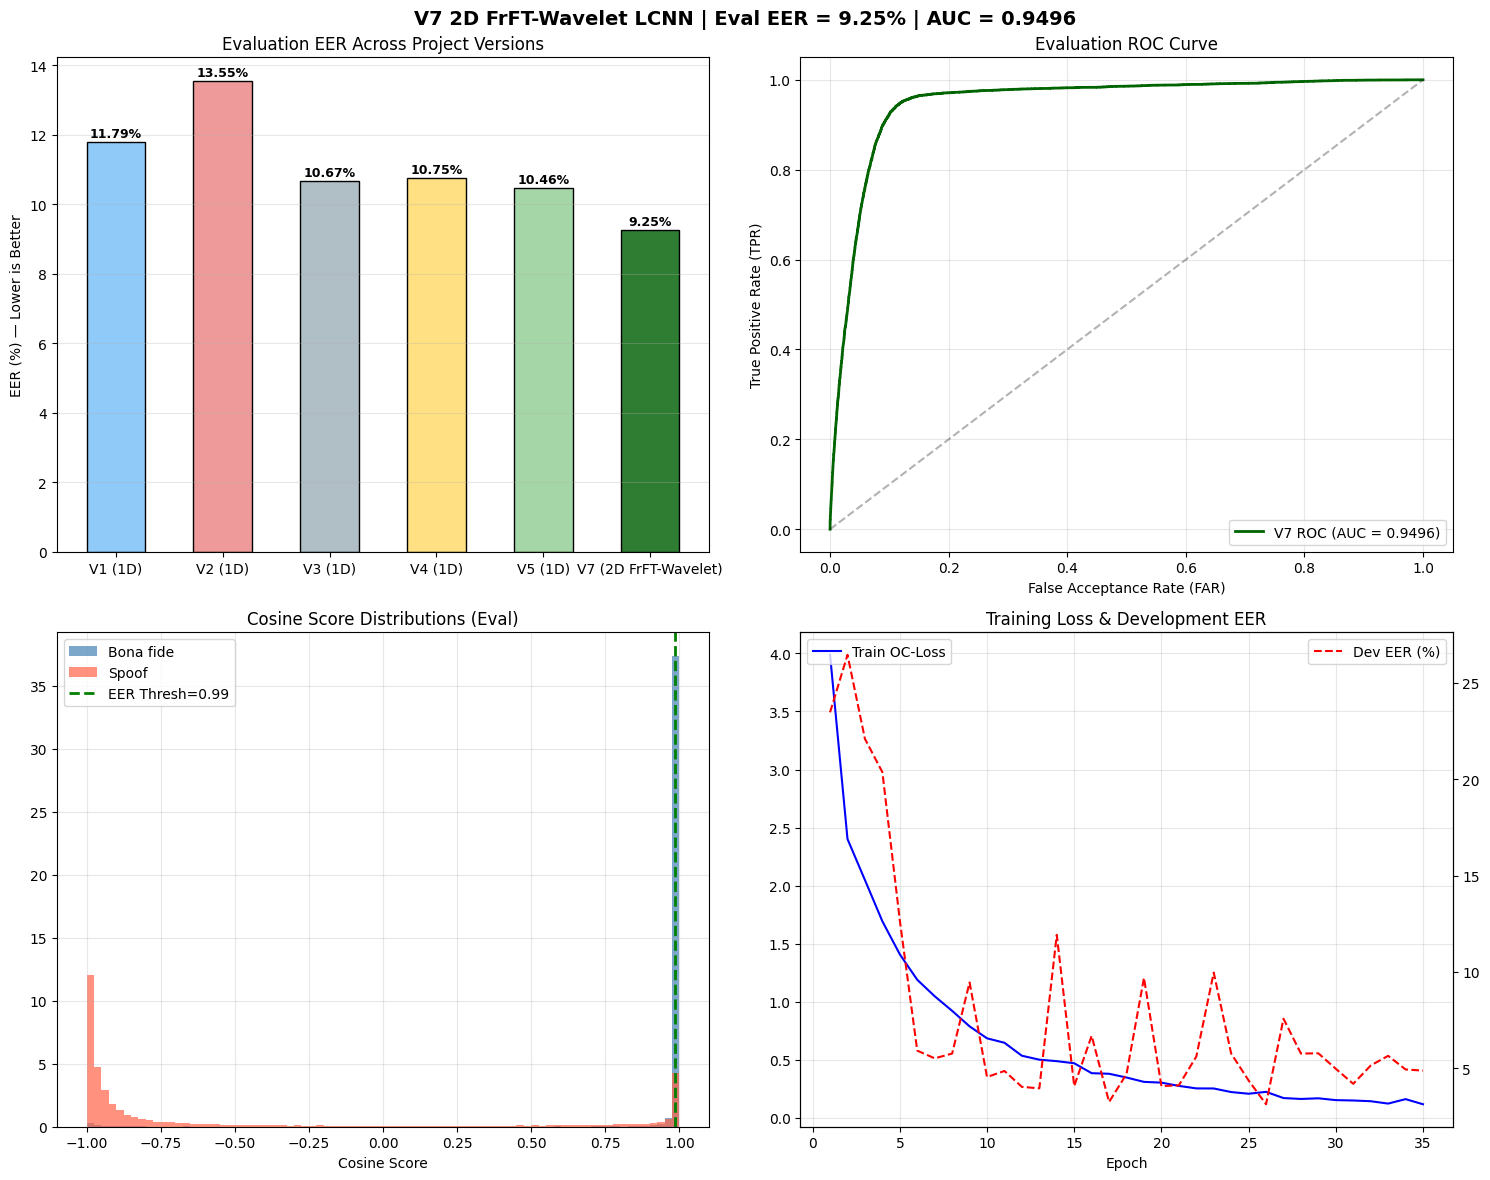

✓ Saved diagnostic visualization to /kaggle/working/v7_results.png
✓ Exported benchmark JSON to /kaggle/working/v7_results.json


In [9]:
# Cell 9: Visualizations and JSON Result Export

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle(f'V7 2D FrFT-Wavelet LCNN | Eval EER = {eval_eer:.2f}% | AUC = {eval_auc:.4f}',
             fontsize=14, fontweight='bold')

# 1. Progression Bar Chart
versions = ['V1 (1D)', 'V2 (1D)', 'V3 (1D)', 'V4 (1D)', 'V5 (1D)', 'V7 (2D FrFT-Wavelet)']
eers     = [11.79, 13.55, 10.67, 10.75, 10.46, eval_eer]
colors   = ['#90CAF9', '#EF9A9A', '#B0BEC5', '#FFE082', '#A5D6A7', '#2E7D32']
bars = axes[0, 0].bar(versions, eers, color=colors, edgecolor='black', width=0.55)
for bar, val in zip(bars, eers):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                    f'{val:.2f}%', ha='center', fontweight='bold', fontsize=9)
axes[0, 0].set_title('Evaluation EER Across Project Versions'); axes[0, 0].set_ylabel('EER (%) — Lower is Better'); axes[0, 0].grid(axis='y', alpha=0.3)

# 2. ROC Curve
fpr, tpr, _ = roc_curve(eval_labels, eval_scores, pos_label=0)
axes[0, 1].plot(fpr, tpr, color='darkgreen', lw=2, label=f'V7 ROC (AUC = {eval_auc:.4f})')
axes[0, 1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[0, 1].set_title('Evaluation ROC Curve'); axes[0, 1].set_xlabel('False Acceptance Rate (FAR)'); axes[0, 1].set_ylabel('True Positive Rate (TPR)'); axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

# 3. Score Distribution
axes[1, 0].hist(eval_scores[eval_labels == 0], bins=80, alpha=0.7, color='steelblue', label='Bona fide', density=True)
axes[1, 0].hist(eval_scores[eval_labels == 1], bins=80, alpha=0.7, color='tomato', label='Spoof', density=True)
axes[1, 0].axvline(eval_thresh, color='green', ls='--', lw=2, label=f'EER Thresh={eval_thresh:.2f}')
axes[1, 0].set_title('Cosine Score Distributions (Eval)'); axes[1, 0].set_xlabel('Cosine Score'); axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

# 4. Training Curves
ep_range = range(1, len(history['loss']) + 1)
axes[1, 1].plot(ep_range, history['loss'], 'b-', lw=1.5, label='Train OC-Loss')
ax2 = axes[1, 1].twinx()
ax2.plot(ep_range, history['dev_eer'], 'r--', lw=1.5, label='Dev EER (%)')
axes[1, 1].set_title('Training Loss & Development EER'); axes[1, 1].set_xlabel('Epoch'); axes[1, 1].legend(loc='upper left'); ax2.legend(loc='upper right'); axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = '/kaggle/working/v7_results.png' if os.path.exists('/kaggle/working') else 'v7_results.png'
plt.savefig(plot_path, dpi=150)
plt.show()
print(f"✓ Saved diagnostic visualization to {plot_path}")

# Results JSON Export
results_v7 = {
    'experiment': 'v7_2d_frft_wavelet_lcnn',
    'representation': '3-Channel 2D Spectrogram (ST-FrFT alpha=0.5, ST-FrFT alpha=0.85, Wavelet Scalogram)',
    'architecture': 'LCNN-2D with MFM-2D activations (170k params)',
    'loss': 'One-Class Softmax (OC-Softmax)',
    'metrics': {
        'best_dev_eer': float(best_dev_eer),
        'eval_eer': float(eval_eer),
        'eval_auc': float(eval_auc),
        'eval_accuracy': float(eval_acc),
        'eval_balanced_accuracy': float(eval_bal_acc)
    }
}
json_path = '/kaggle/working/v7_results.json' if os.path.exists('/kaggle/working') else 'v7_results.json'
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(results_v7, f, indent=2)
print(f"✓ Exported benchmark JSON to {json_path}")
